In [14]:
%pip install scikit-learn-extra

Note: you may need to restart the kernel to use updated packages.


In [15]:
from sklearn_extra.cluster import KMedoids

print("K-Medoids imported successfully!")

K-Medoids imported successfully!


# MSCS 634 Lab 3: Clustering Analysis Using K-Means and K-Medoids

**Name:** Your Name  
**Course:** MSCS 634  
**Lab Assignment:** Lab 3 – K-Means and K-Medoids Clustering

## Objective

The purpose of this lab is to explore clustering techniques using the Wine Dataset
from scikit-learn. K-Means and K-Medoids clustering are applied with three clusters,
corresponding to the three wine classes.

The clustering results are evaluated using the Silhouette Score and Adjusted Rand
Index (ARI). The resulting clusters are also visualized and compared to understand
the strengths and differences between the two algorithms.


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

from sklearn_extra.cluster import KMedoids

print("All libraries loaded successfully!")


All libraries loaded successfully!


In [17]:
wine = load_wine()

X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name="target")

print("Dataset loaded successfully.")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])


Dataset loaded successfully.
Number of samples: 178
Number of features: 13


In [18]:
print("First five rows:")
display(X.head())

print("\nDataset information:")
X.info()

print("\nDescriptive statistics:")
display(X.describe())


First five rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


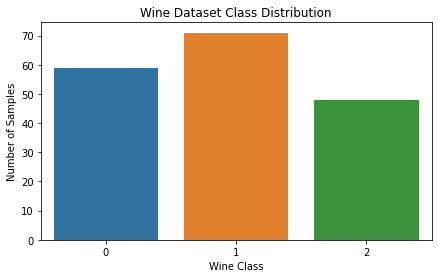

In [19]:
plt.figure(figsize=(7, 4))

sns.countplot(x=y)

plt.title("Wine Dataset Class Distribution")
plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")

plt.show()


In [20]:
print("Missing values by feature:")
print(X.isnull().sum())

print("\nTotal missing values:", X.isnull().sum().sum())


Missing values by feature:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Total missing values: 0


### Missing Value Assessment

The dataset was checked for missing values using `isnull().sum()`. No missing values
were found in the Wine Dataset, so no imputation or row removal was necessary.
This allows the original observations to be retained for clustering.


In [21]:
duplicate_count = X.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)


Number of duplicate rows: 0


### Duplicate Assessment

The dataset was checked for duplicate observations. If duplicates are present, they
should be evaluated before clustering because repeated observations can influence
cluster formation. The duplicate count found above was considered before proceeding
with the analysis.


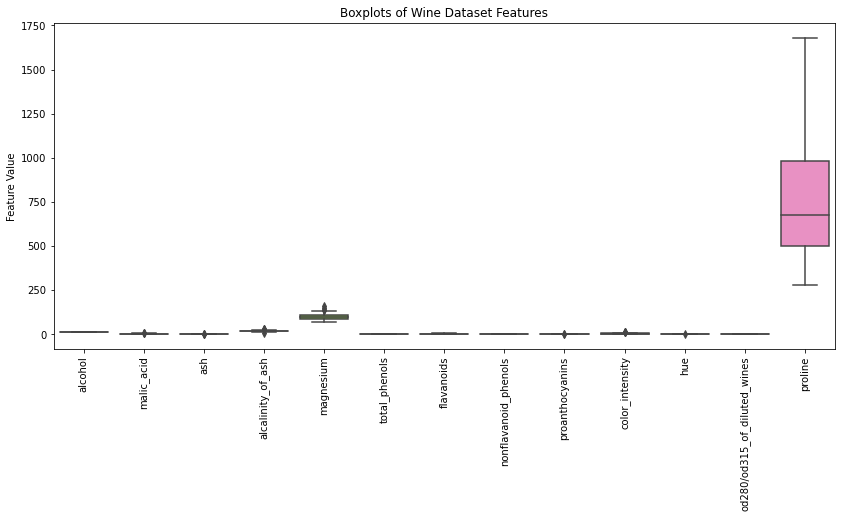

In [22]:
plt.figure(figsize=(14, 6))

sns.boxplot(data=X)

plt.xticks(rotation=90)
plt.title("Boxplots of Wine Dataset Features")
plt.ylabel("Feature Value")

plt.show()


In [23]:
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

IQR = Q3 - Q1

outlier_mask = ((X < (Q1 - 1.5 * IQR)) | 
                (X > (Q3 + 1.5 * IQR)))

print("Potential outliers by feature:")
print(outlier_mask.sum())


Potential outliers by feature:
alcohol                         0
malic_acid                      3
ash                             3
alcalinity_of_ash               4
magnesium                       4
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 2
color_intensity                 4
hue                             1
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64


### Outlier Assessment

Boxplots and the IQR method were used to identify potential outliers. Several
features contain observations outside the conventional 1.5 × IQR range.

The observations were not automatically removed because these values represent
actual wine measurements rather than obvious data-entry errors. Removing valid
observations could eliminate meaningful information from the dataset. Instead,
standardization was used before clustering so that features with larger numerical
scales would not dominate the distance calculations.


In [24]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

display(X_scaled.head())


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


In [25]:
print("Means after standardization:")
print(X_scaled.mean().round(2))

print("\nStandard deviations after standardization:")
print(X_scaled.std().round(2))


Means after standardization:
alcohol                         0.0
malic_acid                      0.0
ash                            -0.0
alcalinity_of_ash              -0.0
magnesium                      -0.0
total_phenols                  -0.0
flavanoids                      0.0
nonflavanoid_phenols           -0.0
proanthocyanins                -0.0
color_intensity                -0.0
hue                             0.0
od280/od315_of_diluted_wines    0.0
proline                        -0.0
dtype: float64

Standard deviations after standardization:
alcohol                         1.0
malic_acid                      1.0
ash                             1.0
alcalinity_of_ash               1.0
magnesium                       1.0
total_phenols                   1.0
flavanoids                      1.0
nonflavanoid_phenols            1.0
proanthocyanins                 1.0
color_intensity                 1.0
hue                             1.0
od280/od315_of_diluted_wines    1.0
proline     

### Standardization

The features were standardized using z-score normalization with `StandardScaler`.
This transforms each feature so that it has approximately mean 0 and standard
deviation 1.

Standardization is important because the Wine Dataset contains variables with
substantially different numerical scales. Without scaling, features with larger
values could disproportionately influence distance-based clustering algorithms.


### Standardization

The features were standardized using z-score normalization with `StandardScaler`.
This transforms each feature so that it has approximately mean 0 and standard
deviation 1.

Standardization is important because the Wine Dataset contains variables with
substantially different numerical scales. Without scaling, features with larger
values could disproportionately influence distance-based clustering algorithms.


In [26]:
k = 3

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-Means cluster labels:")
print(kmeans_labels)


K-Means cluster labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 0 2 2 2 2 2 2 2 2 2 2 2 1
 2 2 2 2 2 2 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 0 2 2 1 2 2 2 2 2 2 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


### K-Means Parameter Selection

The number of clusters was set to `k = 3` because the Wine Dataset contains three
known wine classes. Although clustering is an unsupervised learning technique and
does not use the class labels during training, the known labels can be used afterward
to evaluate how closely the discovered clusters correspond to the actual classes.

A fixed `random_state = 42` was used to make the results reproducible. Multiple
initializations (`n_init = 10`) were used to reduce the chance of obtaining a poor
solution due to the initial centroid positions.


In [27]:
kmeans_silhouette = silhouette_score(
    X_scaled,
    kmeans_labels
)

kmeans_ari = adjusted_rand_score(
    y,
    kmeans_labels
)

print("K-Means Results")
print("-" * 30)
print(f"Silhouette Score: {kmeans_silhouette:.4f}")
print(f"Adjusted Rand Index: {kmeans_ari:.4f}")


K-Means Results
------------------------------
Silhouette Score: 0.2849
Adjusted Rand Index: 0.8975


In [28]:
kmedoids = KMedoids(
    n_clusters=3,
    metric="euclidean",
    method="alternate",
    random_state=42
)

kmedoids_labels = kmedoids.fit_predict(X_scaled)

print("K-Medoids cluster labels:")
print(kmedoids_labels)


K-Medoids cluster labels:
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 1 1 1 2 1 2 1 1 1 2 1 2 1 2
 2 1 1 1 1 2 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 2 0 1 2 1 1 1 1 1 1 1 1 1 1 2 2
 1 1 1 1 1 1 1 1 1 2 2 0 1 2 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [29]:
kmedoids_silhouette = silhouette_score(
    X_scaled,
    kmedoids_labels
)

kmedoids_ari = adjusted_rand_score(
    y,
    kmedoids_labels
)

print("K-Medoids Results")
print("-" * 30)
print(f"Silhouette Score: {kmedoids_silhouette:.4f}")
print(f"Adjusted Rand Index: {kmedoids_ari:.4f}")


K-Medoids Results
------------------------------
Silhouette Score: 0.2660
Adjusted Rand Index: 0.7263


In [30]:
results = pd.DataFrame({
    "Algorithm": ["K-Means", "K-Medoids"],
    "Silhouette Score": [
        kmeans_silhouette,
        kmedoids_silhouette
    ],
    "Adjusted Rand Index": [
        kmeans_ari,
        kmedoids_ari
    ]
})

display(results)


,Algorithm,Silhouette Score,Adjusted Rand Index
0,K-Means,0.284859,0.897495
1,K-Medoids,0.265977,0.726341


In [31]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print(
    f"Variance explained by PC1 and PC2: "
    f"{pca.explained_variance_ratio_.sum():.2%}"
)


Variance explained by PC1 and PC2: 55.41%


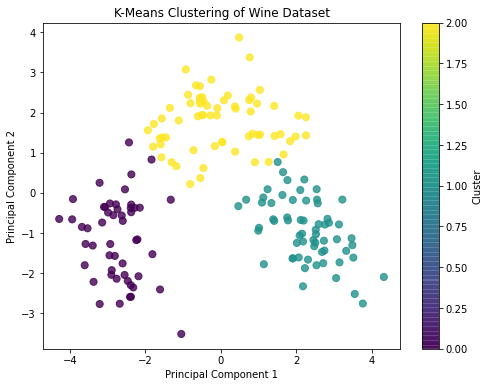

In [32]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=50,
    alpha=0.8
)

plt.title("K-Means Clustering of Wine Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.colorbar(scatter, label="Cluster")

plt.show()


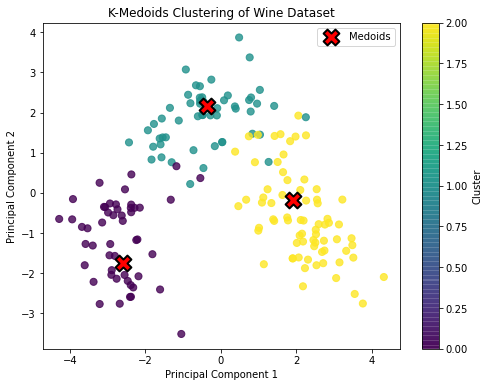

In [33]:
medoid_indices = kmedoids.medoid_indices_

medoid_pca = X_pca[medoid_indices]

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmedoids_labels,
    cmap="viridis",
    s=50,
    alpha=0.8
)

plt.scatter(
    medoid_pca[:, 0],
    medoid_pca[:, 1],
    c="red",
    marker="X",
    s=250,
    edgecolor="black",
    linewidth=2,
    label="Medoids"
)

plt.title("K-Medoids Clustering of Wine Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.colorbar(scatter, label="Cluster")
plt.legend()

plt.show()


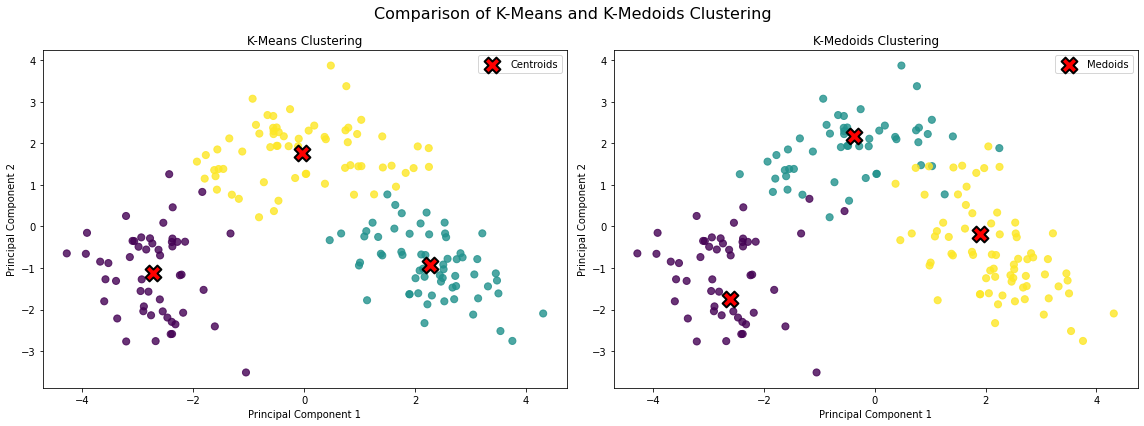

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# K-Means
axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=50,
    alpha=0.8
)

# Transform K-Means centroids into PCA space
centroids_pca = pca.transform(kmeans.cluster_centers_)

axes[0].scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    c="red",
    marker="X",
    s=250,
    edgecolor="black",
    linewidth=2,
    label="Centroids"
)

axes[0].set_title("K-Means Clustering")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
axes[0].legend()

# K-Medoids
axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmedoids_labels,
    cmap="viridis",
    s=50,
    alpha=0.8
)

axes[1].scatter(
    medoid_pca[:, 0],
    medoid_pca[:, 1],
    c="red",
    marker="X",
    s=250,
    edgecolor="black",
    linewidth=2,
    label="Medoids"
)

axes[1].set_title("K-Medoids Clustering")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")
axes[1].legend()

plt.suptitle(
    "Comparison of K-Means and K-Medoids Clustering",
    fontsize=16
)

plt.tight_layout()
plt.show()


## Clustering Comparison

The K-Means and K-Medoids algorithms were both evaluated using the Silhouette Score
and Adjusted Rand Index (ARI).

The algorithm with the higher Silhouette Score produced more clearly separated
clusters according to the internal clustering evaluation. The algorithm with the
higher ARI produced clusters that more closely corresponded to the actual wine
classes.

The PCA visualizations also provide a useful visual comparison of the cluster
structure. K-Means represents each cluster using a centroid calculated from the
observations, while K-Medoids represents each cluster using an actual observation
from the dataset.

K-Means may be preferable when computational efficiency is important and the data
does not contain substantial outliers. K-Means is generally computationally more
efficient than K-Medoids.

K-Medoids may be preferable when robustness to outliers is important or when an
actual observation is preferred as the representative of each cluster. K-Medoids
can also use different distance metrics, which can be useful for some datasets.
